Cell 1: Import Graph libraries

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

Cell 2: load data

In [17]:
graph_df =pd.read_csv(r"D:\Project\Customer-segmentation\results.csv")
temp_df = pd.read_csv(r"D:\Project\Customer-segmentation\segmented_customers.csv")

import pickle

# Load them back instantly
embeddings = np.load(r'D:\Project\Customer-segmentation\embeddings.npy')
final_cluster_labels = np.load(
    r'D:\Project\Customer-segmentation\final_cluster_labels.npy'
)

with open(
    r'D:\Project\Customer-segmentation\history_dict.pkl', 'rb'
) as file_handle:
  history_loss = pickle.load(file_handle)



Cell 3: Plot 1 — Autoencoder Loss Convergence

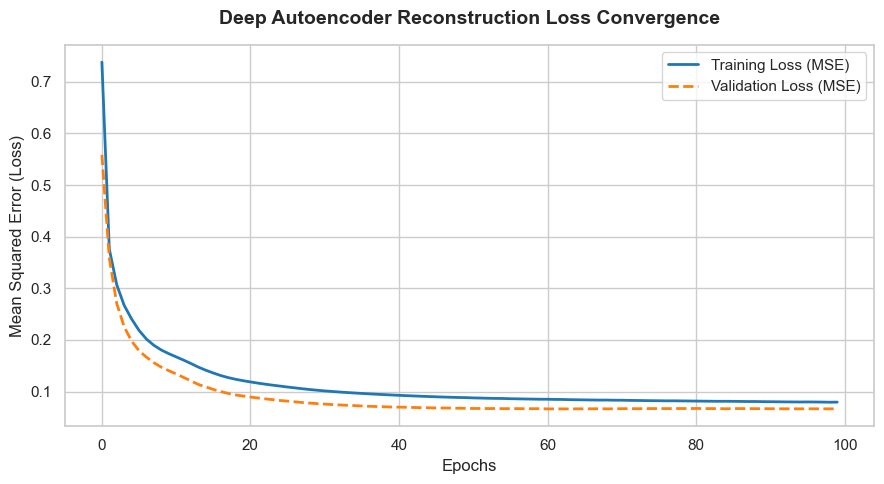

In [18]:
# Set up clean theme
sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

# Plot training and validation loss curves directly from the loaded dictionary
plt.plot(history_loss['loss'], label='Training Loss (MSE)', color='#1f77b4', linewidth=2)
plt.plot(history_loss['val_loss'], label='Validation Loss (MSE)', color='#ff7f0e', linewidth=2, linestyle='--')

# Formatting and Labels
plt.title('Deep Autoencoder Reconstruction Loss Convergence', fontsize=14, weight='bold', pad=15)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Mean Squared Error (Loss)', fontsize=12)
plt.legend(fontsize=11, frameon=True)
plt.tight_layout()

# Save high-resolution figure for your research report
plt.savefig(r'D:\Project\Customer-segmentation\autoencoder_loss_convergence.png', dpi=300, bbox_inches='tight')
plt.show()

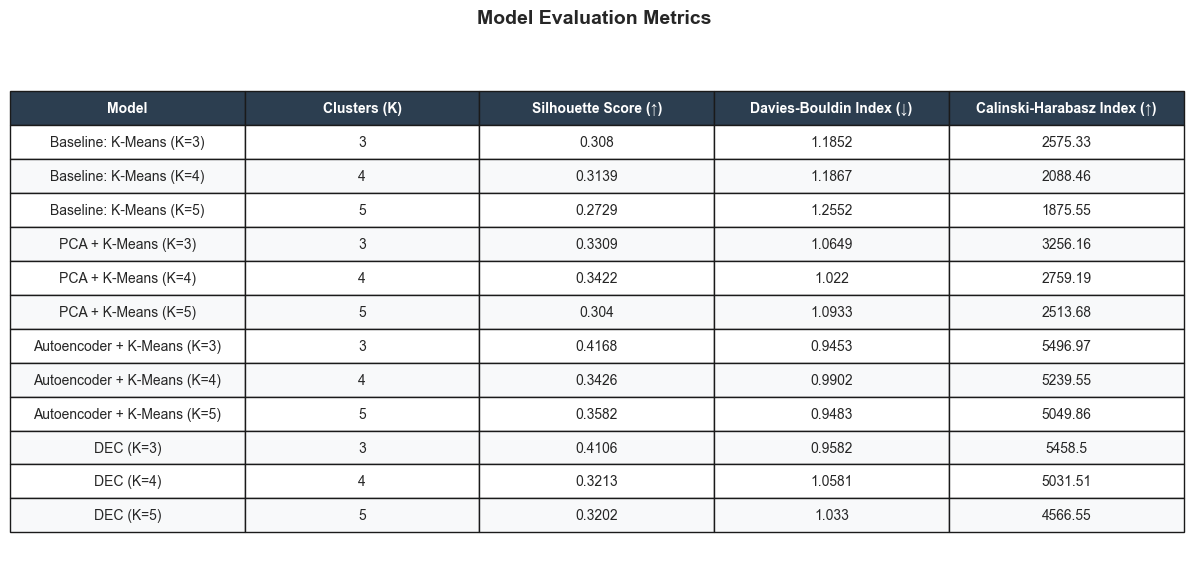

In [19]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.axis('off')
ax.axis('tight')
# Create the table visual
table = ax.table(
    cellText=graph_df.values,
    colLabels=graph_df.columns,
    cellLoc='center',
    loc='center',
)

# Style table properties
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.8)  # Adjust width and height scaling

# Color header row differently
for key, cell in table.get_celld().items():
  if key[0] == 0:
    cell.set_facecolor('#2c3e50')
    cell.set_text_props(color='white', weight='bold')
  else:
    cell.set_facecolor('#f8f9fa' if key[0] % 2 == 0 else '#ffffff')

plt.title(
    'Model Evaluation Metrics ',
    fontsize=14,
    weight='bold',
    pad=20,
)
plt.tight_layout()

# Save image for report
plt.savefig(
    r"D:\Project\Customer-segmentation\graphs\allModelEvaluation.png",
    dpi=300,
    bbox_inches='tight',
)
plt.show()

Cell 3: All Models Across Evaluation Metrics

C:\Users\ASUS\AppData\Local\Temp\ipykernel_38012\3049822167.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_38012\3049822167.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_38012\3049822167.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


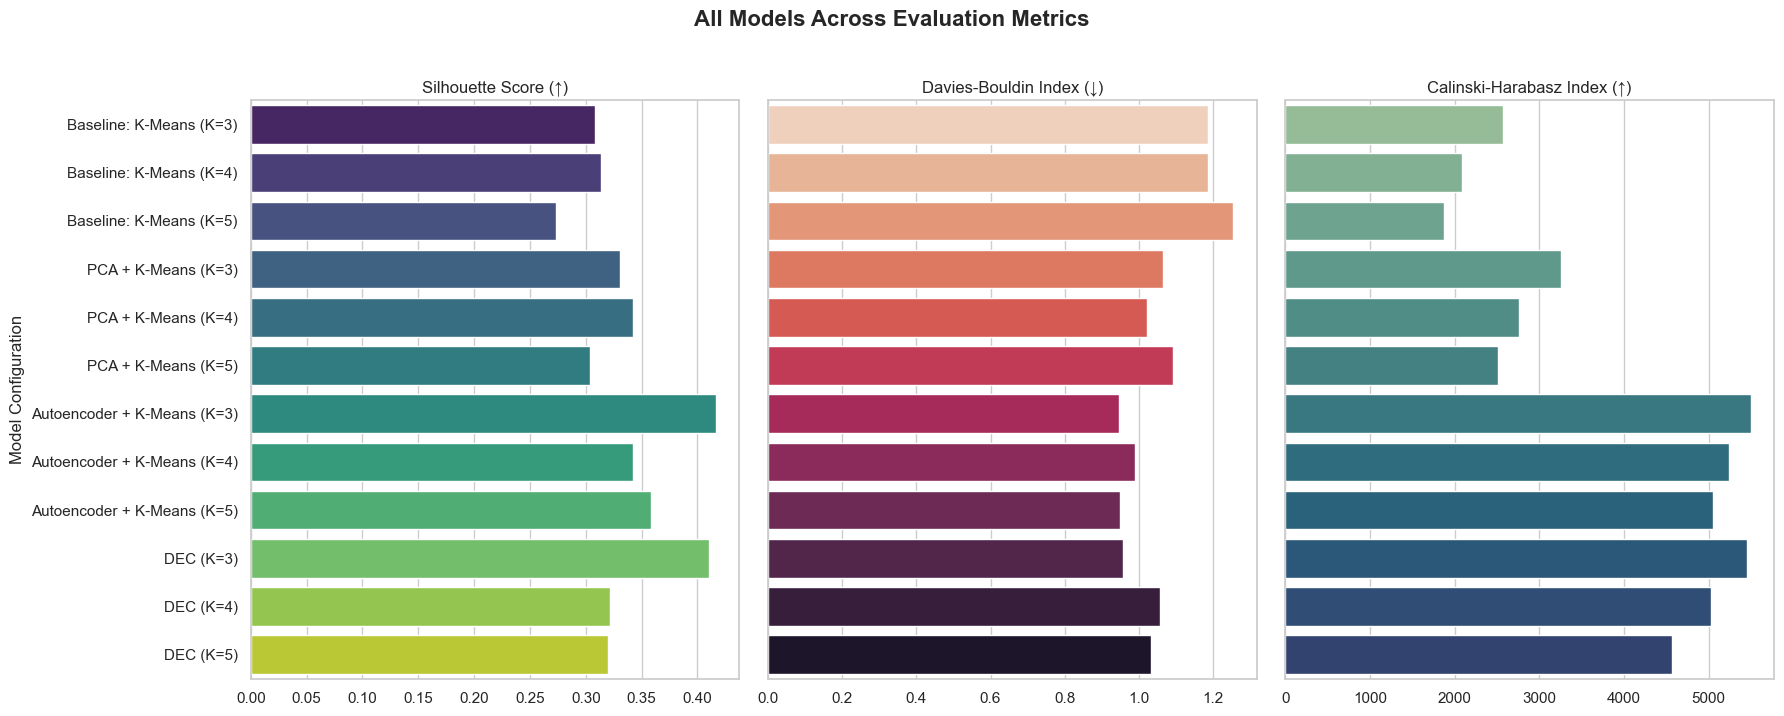

In [20]:
#  Set up a 1-row, 3-column figure grid
fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharey=True)
sns.set_theme(style='whitegrid')

# Panel 1: Silhouette Score (Higher is better)
sns.barplot(
    data=graph_df, x='Silhouette Score (↑)', y='Model', ax=axes[0], palette='viridis'
)
axes[0].set_title('Silhouette Score (↑)', fontsize=12)
axes[0].set_xlabel('')
axes[0].set_ylabel('Model Configuration', fontsize=12)

# Panel 2: Davies-Bouldin Index (Lower is better)
sns.barplot(
    data=graph_df,
    x='Davies-Bouldin Index (↓)',
    y='Model',
    ax=axes[1],
    palette='rocket_r',
)
axes[1].set_title('Davies-Bouldin Index (↓)', fontsize=12)
axes[1].set_xlabel('')
axes[1].set_ylabel('')

# Panel 3: Calinski-Harabasz Index (Higher is better)
sns.barplot(
    data=graph_df,
    x='Calinski-Harabasz Index (↑)',
    y='Model',
    ax=axes[2],
    palette='crest',
)
axes[2].set_title('Calinski-Harabasz Index (↑)', fontsize=12)
axes[2].set_xlabel('')
axes[2].set_ylabel('')

# Overall layout adjustments
plt.suptitle(
    'All Models Across Evaluation Metrics',
    fontsize=16,
    weight='bold',
    y=1.02,
)
plt.tight_layout()
plt.savefig(r"D:\Project\Customer-segmentation\graphs\allModelComparison.png", dpi=300, bbox_inches='tight')


plt.show()

Cell 4: Customer Segments Visualized in 2D PCA Feature Space

<>:5: SyntaxWarning: invalid escape sequence '\P'
<>:5: SyntaxWarning: invalid escape sequence '\P'
C:\Users\ASUS\AppData\Local\Temp\ipykernel_38012\1126209571.py:5: SyntaxWarning: invalid escape sequence '\P'
  temp_df = pd.read_csv("D:\Project\Customer-segmentation\segmented_customers.csv")


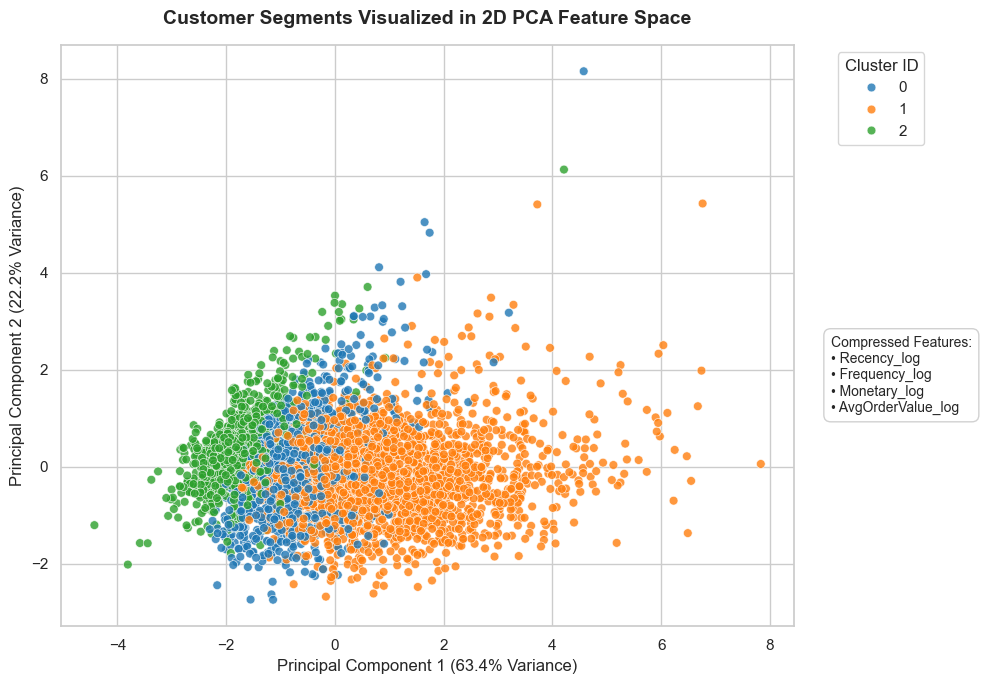

In [21]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


temp_df = pd.read_csv("D:\Project\Customer-segmentation\segmented_customers.csv")

feature_cols = ['Recency_log', 'Frequency_log', 'Monetary_log', 'AvgOrderValue_log']

X = temp_df[feature_cols].values

# Standardize and project features into 2D using PCA for visualization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=42)
coords_2d = pca.fit_transform(X_scaled)

temp_df['PCA1'] = coords_2d[:, 0]
temp_df['PCA2'] = coords_2d[:, 1]

# Create the scatter plot
plt.figure(figsize=(10, 7))
sns.set_theme(style='whitegrid')

sns.scatterplot(
    data=temp_df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='tab10',
    alpha=0.8,
    s=40,
    edgecolor='w',
    linewidth=0.5,
)

# Formatting and Labels
plt.title(
    'Customer Segments Visualized in 2D PCA Feature Space',
    fontsize=14,
    weight='bold',
    pad=15,
)
plt.xlabel(
    f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)',
    fontsize=12,
)
plt.ylabel(
    f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)',
    fontsize=12,
)
features_text = "Compressed Features:\n" + "\n".join(
    [f"• {col}" for col in feature_cols])

leg = plt.legend(
    title="Cluster ID",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=True,
)

plt.text(
    1.05,
    0.5,
    features_text,
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="0.8",
        alpha=0.9,
    ),
)
plt.tight_layout()
plt.savefig(r"D:\Project\Customer-segmentation\graphs\2dPCAscatterPlot", dpi=300, bbox_inches='tight')


plt.show()

C:\Users\ASUS\AppData\Local\Temp\ipykernel_38012\309280257.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_38012\309280257.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_38012\309280257.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\ASUS\AppData\Local\Temp\ipykernel_38012\309280257.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and 

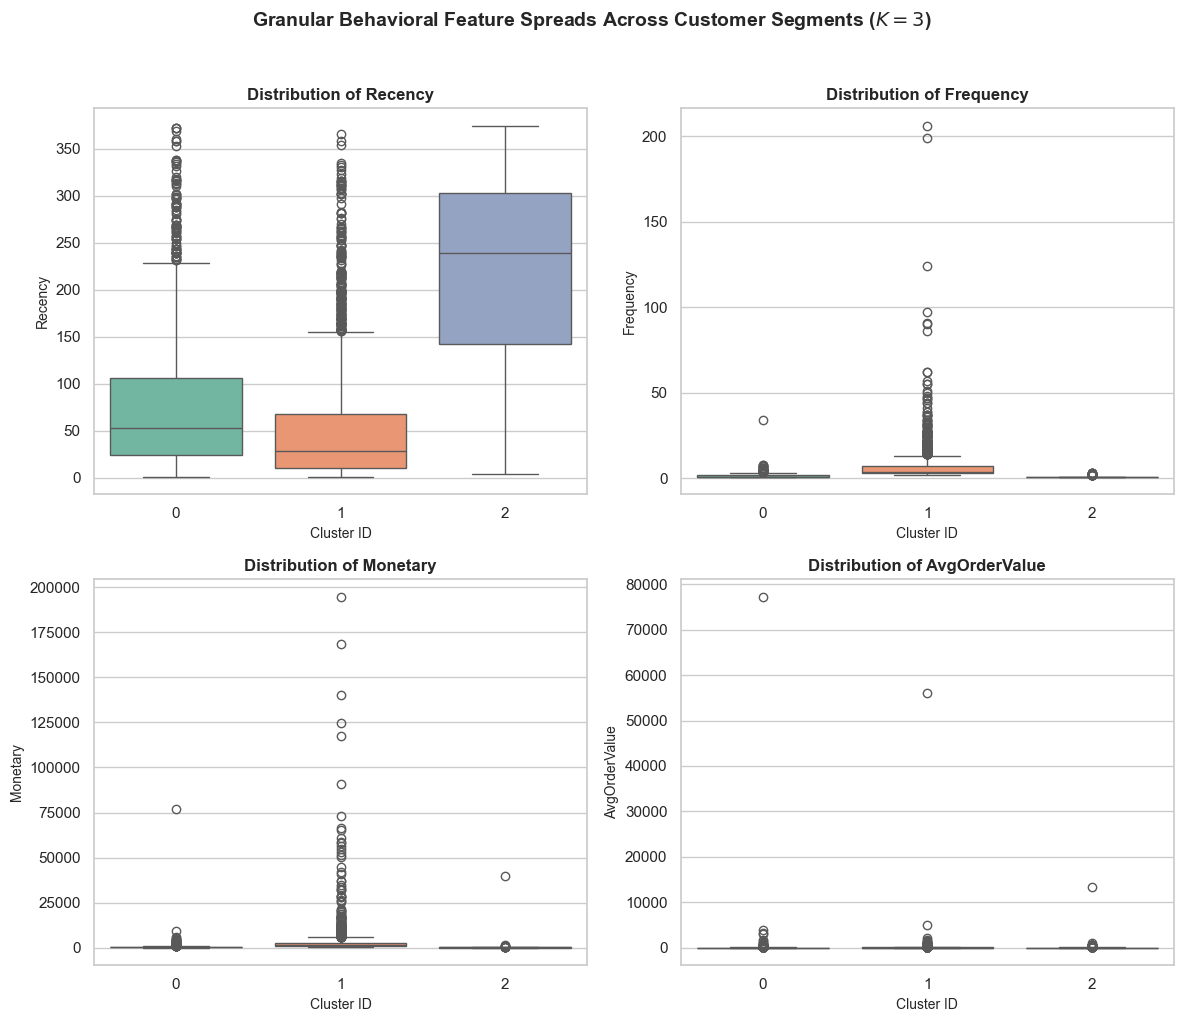

In [ ]:
# Set up clean theme
sns.set_theme(style="whitegrid")

# Identify core RFM features available in your segmented DataFrame
features_to_plot = ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue']
actual_features = [f for f in features_to_plot if f in temp_df.columns]
if not actual_features:
    actual_features = [f'{f}_log' for f in features_to_plot if f'{f}_log' in temp_df.columns]

# Set up a 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, col in enumerate(actual_features[:4]):
    sns.boxplot(
        data=temp_df, 
        x='Cluster', 
        y=col, 
        ax=axes[i], 
        palette='Set2', 
        showfliers=Fasle  # Exclude extreme outliers for cleaner visual comparison
    )
    axes[i].set_title(f'Distribution of {col.replace("_", " ")}', fontsize=12, weight='bold')
    axes[i].set_xlabel('Cluster ID', fontsize=10)
    axes[i].set_ylabel(col.replace('_', ' '), fontsize=10)

plt.suptitle('Granular Behavioral Feature Spreads Across Customer Segments ($K=3$)', fontsize=14, weight='bold', y=1.02)
plt.tight_layout()

# Save high-resolution figure for your research report
plt.savefig(r'D:\Project\Customer-segmentation\feature_spreads_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# In[]: Plot Autoencoder Training & Validation Loss
plt.figure(figsize=(9, 5))
plt.plot(history.history['loss'], label='Training Loss (MSE)', linewidth=2)
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)', linewidth=2, linestyle='--')
plt.title('Autoencoder Reconstruction Loss Convergence', fontsize=14, weight='bold', pad=15)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss (Mean Squared Error)', fontsize=12)
plt.legend(frameon=True, fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(r"D:\Project\Customer-segmentation\graphs\autoencoderLossCurve.png", dpi=300, bbox_inches='tight')
plt.show()

Cell 7:

In [ ]:
# In[]: Behavioral Feature Distributions per Cluster
temp_df = pd.read_csv(r"D:\Project\Customer-segmentation\segmented_customers.csv")
feature_cols = ['Recency_log', 'Frequency_log', 'Monetary_log', 'AvgOrderValue_log']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.boxplot(data=temp_df, x='Cluster', y=col, ax=axes[i], palette='Set2', width=0.5, fliersize=3)
    axes[i].set_title(f'Distribution of {col} by Cluster', fontsize=12, weight='bold')
    axes[i].set_xlabel('Cluster ID', fontsize=10)
    axes[i].set_ylabel(col, fontsize=10)

plt.suptitle('Granular Behavioral Feature Spreads across Customer Segments', fontsize=16, weight='bold', y=1.02)
plt.tight_layout()
plt.savefig(r"D:\Project\Customer-segmentation\graphs\featureBoxplots.png", dpi=300, bbox_inches='tight')
plt.show()

Cell8:

In [ ]:
# In[]: Radar Chart for Customer Segment Personas
from math import pi

# Compute mean values and normalize them between 0 and 1 for the radar chart
cluster_means = temp_df.groupby('Cluster')[['Recency', 'Frequency', 'Monetary', 'AvgOrderValue']].mean()
normalized_means = (cluster_means - cluster_means.min()) / (cluster_means.max() - cluster_means.min())

categories = list(normalized_means.columns)
N = len(categories)

angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for idx, row in normalized_means.iterrows():
    values = row.values.flatten().tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, linestyle='solid', label=f'Cluster {idx}', color=colors[idx])
    ax.fill(angles, values, color=colors[idx], alpha=0.15)

ax.set_theta_offset(pi / 2)
ax.set_theta_direction(-1)
plt.xticks(angles[:-1], categories, color='grey', size=11)
ax.set_rlabel_position(0)
plt.yticks([0.25, 0.5, 0.75], ["0.25", "0.50", "0.75"], color="grey", size=8)
plt.ylim(0, 1)

plt.title('Customer Persona Profiles (Normalized RFM Dimensions)', fontsize=14, weight='bold', pad=25)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), title="Cluster ID")
plt.tight_layout()
plt.savefig(r"D:\Project\Customer-segmentation\graphs\radarChartPersonas.png", dpi=300, bbox_inches='tight')
plt.show()